# 2. Разведочный анализ и подготовка данных

**Автор:** Шинкарев Сергей Дмитриевич, группа о.ИЗДт 23.2/Б3-22  
**Тема ВКР:** «Разработка системы интеллектуального анализа данных мониторинга вузов»

Цель блокнота — понять структуру данных, сформулировать задачу машинного обучения и подготовить выборку.

In [1]:
# Подключаем пакет проекта: блокнот лежит в каталоге notebooks, код — уровнем выше
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

from vuzmon import config
from vuzmon.collect.crawler import load_frames
from vuzmon.tables import consolidate_main
from vuzmon.ml import pipeline, plots, metrics
from vuzmon.ml.dataset import build_samples, build_panel, temporal_split, CLASS_NAMES, HEAD_TARGET_INDICATORS
from vuzmon.config import MAIN_INDICATOR_TITLES

frames = load_frames(config.MONITORING_DIR)
inst, extra = frames["institutions"], frames["extra"]
main = consolidate_main(frames["main"])
print("Паспортов организаций:", len(inst), "| строк основных показателей:", len(main), "| годы:", main.year.min(), "–", main.year.max())

Паспортов организаций: 6127 | строк основных показателей: 11508 | годы: 2017 – 2025


## 2.1. Состав организаций

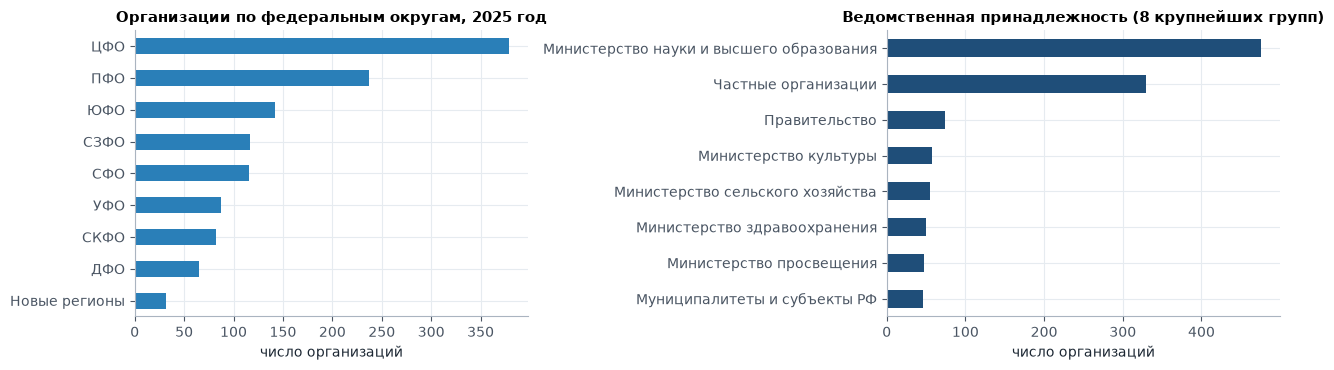

In [2]:
last = inst[inst.year == inst.year.max()]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
last.groupby("federal_district").size().sort_values().plot.barh(ax=axes[0], color=plots.COLORS["accent"])
axes[0].set(title="Организации по федеральным округам, 2025 год", xlabel="число организаций", ylabel="")
founders = last["founder_group"].str.replace(" Российской Федерации", "").value_counts().head(8).sort_values()
founders.plot.barh(ax=axes[1], color=plots.COLORS["primary"])
axes[1].set(title="Ведомственная принадлежность (8 крупнейших групп)", xlabel="число организаций", ylabel="")
plt.tight_layout(); plt.show()

## 2.2. Основные показатели эффективности

Показатели сильно различаются по масштабу и имеют «тяжёлые хвосты»: у небольшого числа вузов значения на порядок выше типичных.
Поэтому при подготовке признаков используется логарифмирование и отношение к медиане.

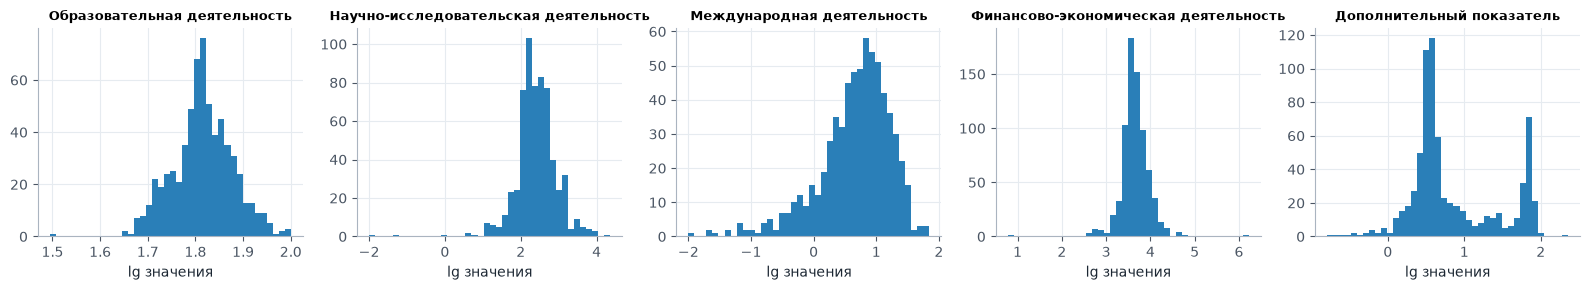

,count,mean,std,min,25%,50%,75%,max
e1,733.0,58.56,22.79,0.00,56.08,64.30,70.82,100.00
e2,733.0,454.46,1164.13,0.00,79.70,189.99,428.07,22645.11
e3,733.0,7.63,8.72,0.00,1.66,4.91,10.60,70.40
e4,733.0,7934.82,61096.65,5.97,3191.57,4337.46,6581.60,1654042.71
e8,733.0,17.87,26.65,0.00,3.01,4.02,19.18,226.67


In [3]:
heads = main.merge(inst[["inst_id", "year", "is_branch"]], on=["inst_id", "year"])
heads = heads[(heads.is_branch == 0) & (heads.year == 2025)]
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for axis, code in zip(axes, HEAD_TARGET_INDICATORS):
    values = heads[code].dropna()
    axis.hist(np.log10(values[values > 0]), bins=40, color=plots.COLORS["accent"])
    axis.set_title(MAIN_INDICATOR_TITLES[code].split(" (")[0], fontsize=9); axis.set_xlabel("lg значения")
plt.tight_layout(); plt.show()
heads[list(HEAD_TARGET_INDICATORS)].describe().T.round(2)

In [4]:
# Доля нулевых и отсутствующих значений: ноль часто означает «показатель не рассчитан»
zero = (heads[list(HEAD_TARGET_INDICATORS)] == 0).mean().rename("доля нулей")
missing = heads[list(HEAD_TARGET_INDICATORS)].isna().mean().rename("доля пропусков")
pd.concat([zero, missing], axis=1).round(3).T

,e1,e2,e3,e4,e8
доля нулей,0.113,0.153,0.086,0.0,0.022
доля пропусков,0.000,0.000,0.000,0.0,0.000


## 2.3. Постановка задачи

Для каждой головной организации считаем, сколько из пяти основных показателей (E.1, E.2, E.3, E.4, E.8)
**не ниже медианы по России**, и относим её к одному из трёх классов:

| Класс | Выполнено показателей |
|---|---|
| 0 — зона риска | 0–1 |
| 1 — средний уровень | 2–3 |
| 2 — лидеры | 4–5 |

**Задача:** по данным года *t* предсказать класс организации в году *t + 1*. Это задача многоклассовой классификации
с упорядоченными классами; практический смысл — заранее увидеть вузы, которым грозит ухудшение положения.

Объектов «организация — год»: 3531 | признаков: 138 | с известным ответом: 2717


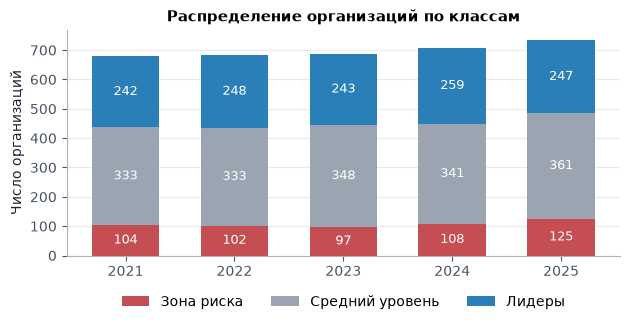

,Зона риска,Средний уровень,Лидеры
year,,,
2021,104,333,242
2022,102,333,248
2023,97,348,243
2024,108,341,259
2025,125,361,247


In [5]:
samples = build_samples(frames)
print("Объектов «организация — год»:", len(samples), "| признаков:", samples.features.shape[1], "| с известным ответом:", int(samples.target.notna().sum()))
table = samples.meta.dropna(subset=["current_class"]).groupby(["year", "current_class"]).size().unstack()
table.columns = CLASS_NAMES
plots.class_distribution(list(table.index), table.to_numpy(), CLASS_NAMES); plt.show()
table

## 2.4. Насколько класс устойчив во времени

Матрица переходов показывает, как часто организация остаётся в своём классе на следующий год.

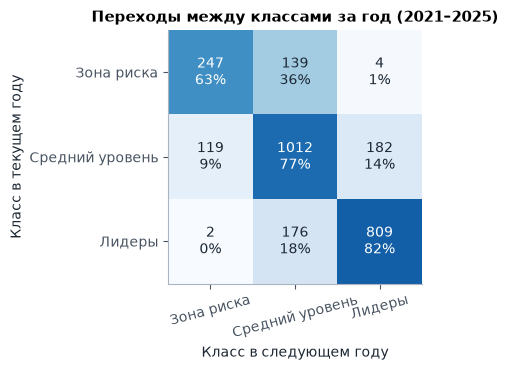

Доля организаций, сохранивших класс, по годам:
year
2021    0.734
2022    0.766
2023    0.748
2024    0.796


In [6]:
labeled = samples.labeled()
known = labeled.meta["current_class"].notna()      # у нескольких организаций нет данных текущего года
transitions = pd.crosstab(labeled.meta.loc[known, "current_class"].astype(int), labeled.target[known].astype(int))
plots.confusion_matrix(transitions.to_numpy(), CLASS_NAMES, "Переходы между классами за год (2021–2025)",
                       xlabel="Класс в следующем году", ylabel="Класс в текущем году"); plt.show()
stay = (labeled.meta["current_class"] == labeled.target)
print("Доля организаций, сохранивших класс, по годам:")
print(stay.groupby(labeled.meta["year"]).mean().round(3).to_string())

**Вывод.** Около 75–80 % организаций сохраняют класс. Значит, наивный прогноз «в следующем году класс не изменится»
уже даёт высокую долю верных ответов, и именно с ним нужно сравнивать модели. Ценность модели — в оставшихся 20–25 %
случаев и в **вероятностях**: наивный прогноз не умеет сказать, какие организации находятся у границы класса.

## 2.5. Признаки: близость к границе класса

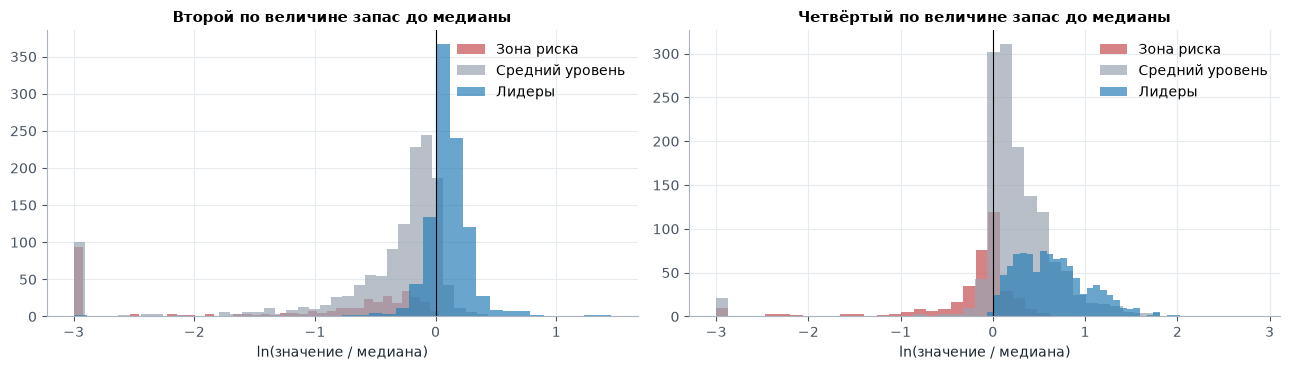

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for label, color in zip(range(3), plots.CLASS_COLORS):
    part = labeled.features.loc[(labeled.target == label).to_numpy(), "margin_sorted_2"]
    axes[0].hist(part, bins=40, alpha=0.7, color=color, label=CLASS_NAMES[label])
    part = labeled.features.loc[(labeled.target == label).to_numpy(), "margin_sorted_4"]
    axes[1].hist(part, bins=40, alpha=0.7, color=color, label=CLASS_NAMES[label])
axes[0].set(title="Второй по величине запас до медианы", xlabel="ln(значение / медиана)")
axes[1].set(title="Четвёртый по величине запас до медианы", xlabel="ln(значение / медиана)")
for axis in axes: axis.axvline(0, color="black", linewidth=0.8); axis.legend()
plt.tight_layout(); plt.show()

«Запас» показателя — логарифм отношения его значения к медиане. Класс меняется, когда через ноль переходит второй
(граница «зона риска / средний уровень») или четвёртый (граница «средний уровень / лидеры») по величине запас,
поэтому упорядоченные запасы хорошо разделяют классы следующего года.

In [8]:
# Связь признаков с классом следующего года: коэффициент ранговой корреляции Спирмена
corr = labeled.features.corrwith(labeled.target, method="spearman").dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)
from vuzmon.ml.explain import feature_title
titles = dict(zip(frames["dictionary"]["column"], frames["dictionary"]["name"]))
pd.DataFrame({"признак": [feature_title(name, titles)[:90] for name in top.index], "корреляция": top.round(3).to_numpy()})

,признак,корреляция
0,Число выполненных основных показателей в текущ...,0.759
1,margin_sorted_2,0.733
2,margin_sorted_3,0.711
3,margin_sorted_4,0.613
4,margin_sorted_1,0.596
5,e2_margin,0.542
6,Научно-исследовательская деятельность: отношен...,0.539
7,"Общий объем средств, поступивших (за отчетный ...",0.535
8,"Общий объем средств, поступивших (за отчетный ...",0.522
9,e2_margin_lag1,0.507


## 2.6. Пропуски и предобработка

In [9]:
share = samples.features.isna().mean().sort_values(ascending=False)
print("Признаков с пропусками:", int((share > 0).sum()), "из", len(share))
share.head(10).round(3).rename("доля пропусков").to_frame().T

Признаков с пропусками: 86 из 138


,e2_growth,e1_growth,e3_growth,e8_ratio_lag2,e1_ratio_lag2,e4_ratio_lag2,e2_ratio_lag2,e3_ratio_lag2,e8_growth,e8_ratio_lag1
доля пропусков,0.112,0.111,0.074,0.058,0.054,0.054,0.054,0.054,0.052,0.042


In [10]:
prepared = pipeline.prepare_data(frames)
pre = prepared.preprocessor
print("Логарифмируется признаков:", len(pre.log_columns), "| добавлено флагов пропуска:", len(pre.flag_columns),
      "| итоговая размерность:", len(pre.feature_names))
pd.DataFrame({name: {"годы": info["years"], "объектов": info["rows"], "по классам": info.get("classes", "—")}
              for name, info in prepared.summary().items() if name != "n_features"}).T

Логарифмируется признаков: 68 | добавлено флагов пропуска: 14 | итоговая размерность: 152


,годы,объектов,по классам
train,"[2021, 2022]",1348,"[192, 667, 489]"
val,[2023],674,"[83, 332, 259]"
test,[2024],695,"[101, 347, 247]"
future,[2025],736,—


Разбиение выполняется **по времени**: модель обучается на более ранних годах и проверяется на более поздних —
так, как она будет применяться на практике. Параметры предобработки (медианы, средние, стандартные отклонения)
вычисляются только по обучающей части, чтобы сведения из проверочных лет не «протекали» в модель.

In [11]:
naive = pipeline.persistence_reports(prepared)
pd.DataFrame({part: {key: round(naive[part][key], 3) for key in ("accuracy", "balanced_accuracy", "macro_f1", "macro_auc", "log_loss")}
              for part in ("val", "test")}).rename(columns={"val": "наивный прогноз, валидация", "test": "наивный прогноз, тест"})

,"наивный прогноз, валидация","наивный прогноз, тест"
accuracy,0.754,0.796
balanced_accuracy,0.721,0.782
macro_f1,0.719,0.778
macro_auc,0.791,0.834
log_loss,1.149,0.957


## 2.7. Выводы

* Набор данных пригоден для обучения: 2 717 объектов с известным ответом, 138 исходных признаков (152 после предобработки).
* Классы умеренно несбалансированы: «зона риска» — около 14 % объектов.
* Класс инерционен: наивный прогноз даёт 79,6 % верных ответов на тестовом годе. Это нижняя планка для моделей.
* Самые информативные признаки — запасы показателей до медианы и их порядковые статистики.